# Assignment 2, Task 3b: Grad-CAM and Comparison with LRP

**Author:** Yeap Jie Shen (22062548)
**Course:** WQF7009 Explainable Artificial Intelligence, Assignment 2

**Objective:** explain the same VGG16 brain tumour classifier with a second method, Gradient-weighted Class Activation Mapping (Grad-CAM; Selvaraju et al., 2017), and compare it with the LRP explanations of [notebook 05](05_vgg16_lrp.ipynb).

**Approach:**
- Load the weights saved by [notebook 05](05_vgg16_lrp.ipynb#sec-training); same test sets (Original, Clean\*), case rule and main case (`meningioma_tumor/image(88).jpg`).
- Explain each image for its predicted class with both methods.
- Compare the methods on the same cases, on misclassified images, on a deletion test of faithfulness and on how much evidence falls outside the head.

**Contents**
1. [Setup](#sec-setup)
2. [Grad-CAM explainer](#sec-gradcam)
3. [Local explanations: LRP vs Grad-CAM](#sec-local)
4. [Main case](#sec-main)
5. [Misclassified images](#sec-errors)
6. [Faithfulness: deletion test](#sec-deletion)
7. [Region relevance: evidence outside the head](#sec-background)
8. [Comparison](#sec-comparison)
9. [Key takeaways](#sec-takeaways)
10. [References](#sec-references)

<a id="sec-setup"></a>

## 1. Setup

- Test sets, modality\* and case rule as in [notebook 05](05_vgg16_lrp.ipynb#sec-setup).

\* Based on the author's visual judgement (not a radiologist), see [notebook 04](04_mri_eda.ipynb#sec-ct).

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from captum.attr import LayerAttribution, LayerGradCam
from scipy.stats import spearmanr

from brain_mri_xai import SEED
from brain_mri_xai.data import (
    CLASS_LABELS,
    CLASSES,
    annotate_test,
    flag_duplicates,
    index_images,
    load_images,
    normalise,
    split_train_validation,
)
from brain_mri_xai.explain import GRADCAM_LAYER, block_sums, grad_cam, lrp
from brain_mri_xai.model import (
    device,
    load_model,
    median_confidence_case,
    predict_proba,
    randomise_top_layers,
)
from brain_mri_xai.plotting import lrp_heatmap, show_grad_cam, show_image, show_lrp
from stroke_shap.plotting import COLORS, FIGURE_WIDTH, label_panels, save_figure, set_theme

set_theme()
LABELS = [CLASS_LABELS[c] for c in CLASSES]
MAIN_CLASS = "meningioma_tumor"  # main case class, as in notebook 05

index = flag_duplicates(index_images())
test = annotate_test(index, split_train_validation(index))
assert len(test) == 394 and test["clean"].sum() == 291
TEST_SETS = {"Original": test.index, "Clean*": test.index[test["clean"]]}
test_images = load_images(test["path"])
model = load_model()
probabilities = predict_proba(model, test_images)
test["predicted"] = probabilities.argmax(1)
test["confidence"] = probabilities.max(1)
test["correct"] = test["predicted"] == test["target"]
test["file"] = test["path"].map(lambda p: f"{p.parent.name}/{p.name}")

candidates = test[test["correct"] & test["clean"] & (test["modality"] == "MRI")]  # case rule of notebook 05
cases = {label: median_confidence_case(candidates[candidates["label"] == label]) for label in CLASSES}
main = cases[MAIN_CLASS]

<a id="sec-gradcam"></a>

## 2. Grad-CAM explainer

- **Layer:** the 512 feature maps $A^k$ of the last convolutional block (conv5_3 after its ReLU, `GRADCAM_LAYER=29`); 14 x 14 cells of 16 x 16 pixels.
- **Weights:** gradient of the class logit $y^c$, averaged over the $Z$ cells of each map: $\alpha_k^c = \frac{1}{Z}\sum_{i,j} \frac{\partial y^c}{\partial A^k_{ij}}$.
- **Map:** $L^c = \mathrm{ReLU}\left(\sum_k \alpha_k^c A^k\right)$, upsampled to 224 x 224 (bilinear) and scaled to a maximum of 1.
- **Output:** coarse (one value per 16 x 16 block, smoothed); shows only evidence **for** the class.
- **Checks** on the same 40 test images as in [notebook 05](05_vgg16_lrp.ipynb#sec-checks):
  - the hand-written `brain_mri_xai.explain.grad_cam` against Captum's `LayerGradCam` (Kokhlikyan et al., 2020);
  - the model-randomisation test (Adebayo et al., 2018), with the LRP result alongside.

- **Captum:** the hand-written Grad-CAM matches `LayerGradCam` exactly (largest absolute difference 0); median 0.013 s per image (40 check images).
- **Randomisation:** Grad-CAM maps no longer resemble the originals (median rank correlation -0.110; 6 of 40 maps become all zero), while LRP maps still do (0.690).
- **Implication:** Grad-CAM passes the check and LRP fails it: Grad-CAM shows what the trained top layers use, LRP also shows image structure that remains with random top layers.

In [2]:
N_CHECK = 40
check_ids = np.random.default_rng(SEED).choice(len(test), size=N_CHECK, replace=False)
captum_cam = LayerGradCam(model, model.features[GRADCAM_LAYER])
random_model = randomise_top_layers(load_model())
differences, seconds, randomisation = [], [], []
for i in check_ids:
    image, target = normalise(test_images[i]), int(test.loc[i, "predicted"])
    start = time.perf_counter()
    ours = grad_cam(model, image, target)
    seconds.append(time.perf_counter() - start)
    theirs = captum_cam.attribute(
        image.unsqueeze(0).to(device()).requires_grad_(True), target=target, relu_attributions=True
    )
    theirs = LayerAttribution.interpolate(theirs, image.shape[-2:], "bilinear")[0, 0].detach().cpu().numpy()
    theirs = theirs / theirs.max() if theirs.max() > 0 else theirs
    differences.append(np.abs(ours - theirs).max())
    lrp_original = np.abs(lrp_heatmap(lrp(model, image, target)))
    lrp_random = np.abs(lrp_heatmap(lrp(random_model, image, target)))
    cam_random = grad_cam(random_model, image, target)
    randomisation.append(
        (
            spearmanr(block_sums(lrp_original), block_sums(lrp_random))[0],
            spearmanr(block_sums(ours), block_sums(cam_random))[0] if cam_random.max() > 0 else np.nan,
        )
    )
randomisation = pd.DataFrame(randomisation, columns=["LRP", "Grad-CAM"])
pd.Series(
    {
        "Images checked": N_CHECK,
        "Grad-CAM vs Captum, max absolute difference": f"{max(differences):.1e}",
        "Grad-CAM median seconds per image (40 check images)": f"{np.median(seconds):.3f}",
        "Median rank correlation after randomisation, LRP": f"{randomisation['LRP'].median():.2f}",
        "Median rank correlation after randomisation, Grad-CAM": f"{randomisation['Grad-CAM'].median():.2f}",
        "Grad-CAM maps all zero after randomisation": int(randomisation["Grad-CAM"].isna().sum()),
    },
    name="Value",
).to_frame()

,Value
Images checked,40
"Grad-CAM vs Captum, max absolute difference",0.0e+00
Grad-CAM median seconds per image (40 check images),0.013
"Median rank correlation after randomisation, LRP",0.69
"Median rank correlation after randomisation, Grad-CAM",-0.11
Grad-CAM maps all zero after randomisation,6


<a id="sec-local"></a>

## 3. Local explanations: LRP vs Grad-CAM

- The four typical correct cases of [notebook 05](05_vgg16_lrp.ipynb#sec-local), explained by both methods.
- Reading of the heatmaps is the author's visual judgement (not a radiologist).

- **Glioma:** both methods mark the enhancing lesion; LRP also marks the skull ring.
- **Meningioma** (main case): LRP marks the tumour edge, Grad-CAM the tumour body.
- **No Tumour:** Grad-CAM covers the front and centre of the brain, plus a patch of background below the head; LRP is spread over the brain. Neither points to a specific structure, consistent with a judgement about the overall appearance.
- **Pituitary:** Grad-CAM lights up tissue on both sides of the brain, not the tumour in the middle, and LRP leaves the tumour neutral. Both agree that this correct prediction does not rest on the tumour.

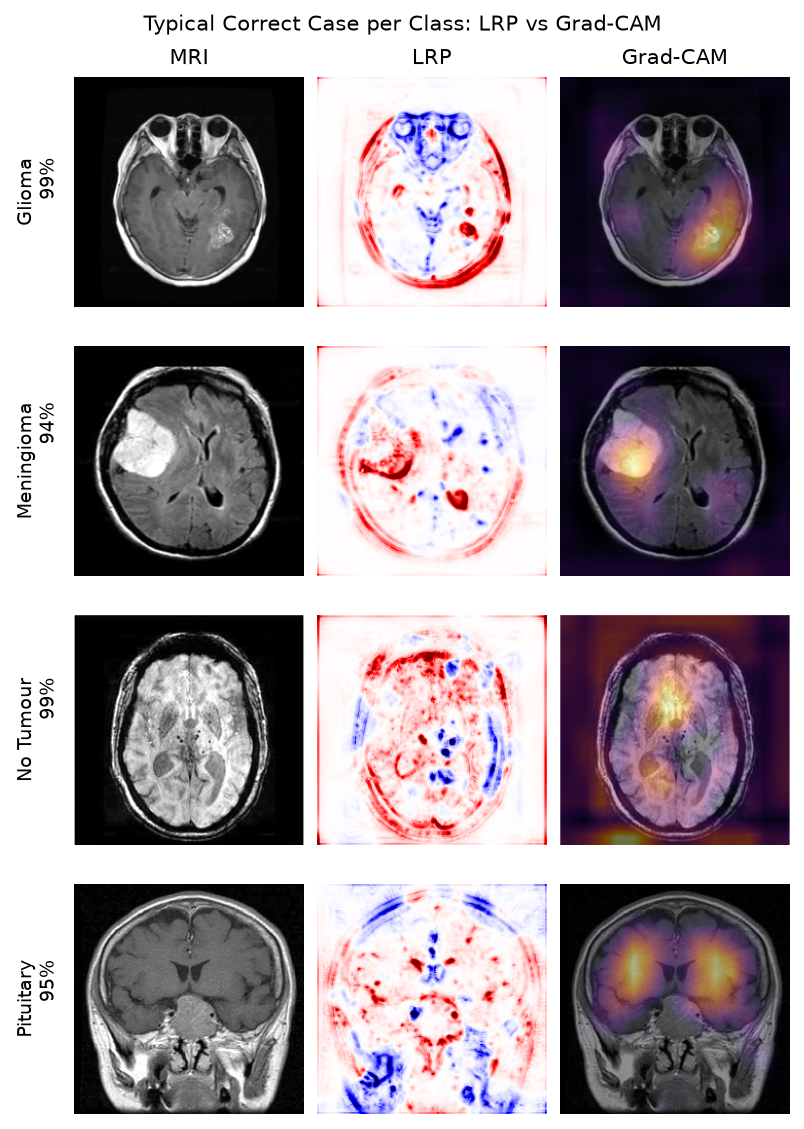

In [3]:
fig, axes = plt.subplots(len(CLASSES), 3, figsize=(FIGURE_WIDTH * 0.75, FIGURE_WIDTH * 0.75 * 4 / 3 + 0.5))
for row, (label, i) in zip(axes, cases.items(), strict=True):
    image, target = normalise(test_images[i]), int(test.loc[i, "predicted"])
    show_image(row[0], image)
    show_lrp(row[1], lrp_heatmap(lrp(model, image, target)))
    show_grad_cam(row[2], image, grad_cam(model, image, target))
    row[0].text(
        -0.06,
        0.5,
        f"{CLASS_LABELS[label]}\n{test.loc[i, 'confidence']:.0%}",
        transform=row[0].transAxes,
        rotation=90,
        ha="right",
        va="center",
    )
for ax, title in zip(axes[0], ["MRI", "LRP", "Grad-CAM"], strict=True):
    ax.set_title(title)
fig.suptitle("Typical Correct Case per Class: LRP vs Grad-CAM")
save_figure(fig, "06_cases")

<a id="sec-main"></a>

## 4. Main case

- **Prediction:** Meningioma 94.3%, No Tumour 5.6%.
- **Result:** the methods agree. LRP marks the lower boundary of the bright tumour in red; Grad-CAM's strongest region covers the lower part of the tumour body.
- **Implication:** on this scan the prediction rests on the lesion, not on the skull or the background. This is the case explained in the slides.

,Predicted probability
Glioma,0.0%
Meningioma,94.3%
No Tumour,5.6%
Pituitary,0.0%


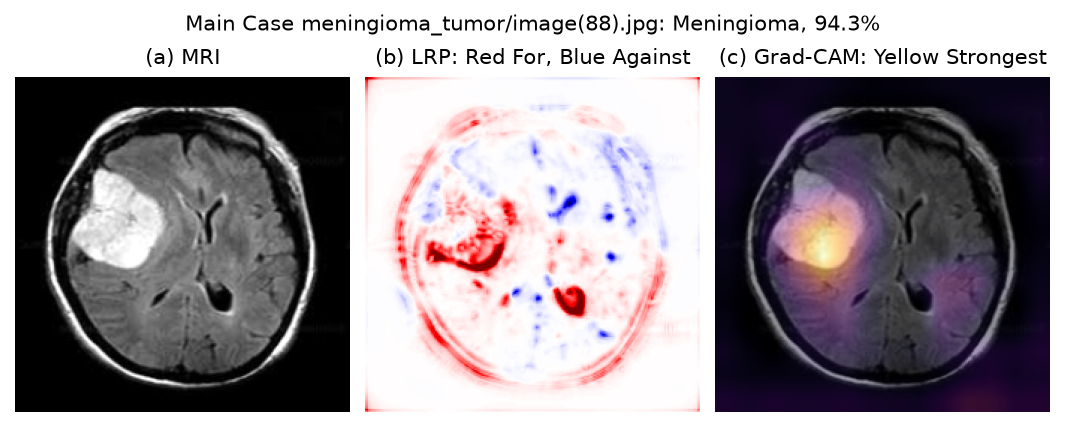

In [4]:
image, target = normalise(test_images[main]), int(test.loc[main, "predicted"])
main_lrp = lrp_heatmap(lrp(model, image, target))
main_cam = grad_cam(model, image, target)
fig, axes = plt.subplots(1, 3, figsize=(FIGURE_WIDTH, FIGURE_WIDTH / 3 + 0.4))
show_image(axes[0], image)
show_lrp(axes[1], main_lrp)
show_grad_cam(axes[2], image, main_cam)
for ax, title in zip(axes, ["MRI", "LRP: Red For, Blue Against", "Grad-CAM: Yellow Strongest"], strict=True):
    ax.set_title(title, fontsize=9)
label_panels(axes)
fig.suptitle(f"Main Case {test.loc[main, 'file']}: {LABELS[target]}, {test.loc[main, 'confidence']:.1%}")
save_figure(fig, "06_main_case")
pd.Series(probabilities[main], index=LABELS, name="Predicted probability").map("{:.1%}".format).to_frame()

- Same case for the patient slide: scan and Grad-CAM overlay only, plain titles.

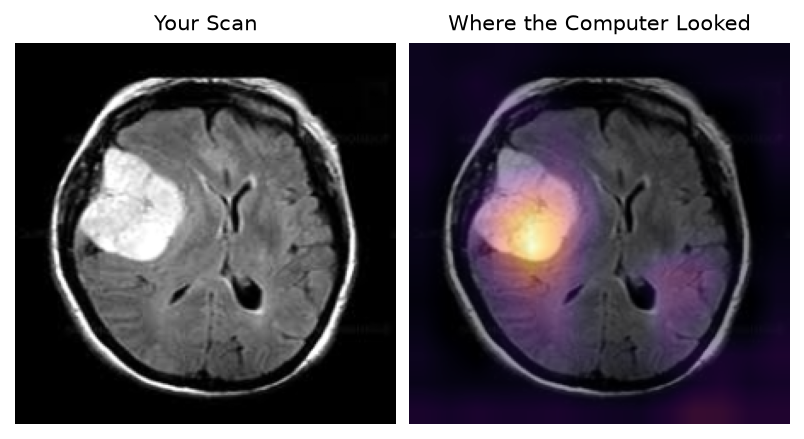

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(FIGURE_WIDTH * 0.75, FIGURE_WIDTH * 0.375 + 0.2))
show_image(axes[0], image)
show_grad_cam(axes[1], image, main_cam)
axes[0].set_title("Your Scan")
axes[1].set_title("Where the Computer Looked")
save_figure(fig, "06_patient_view")

<a id="sec-errors"></a>

## 5. Misclassified images

- **Error types:** counted on the Original test set, with the number of CT\* images per type.
- **Case selection:** the two most frequent error types in the [test confusion matrix](05_vgg16_lrp.ipynb#sec-performance); within each, the MRI\* image with the median confidence.
- **Confidently wrong:** the Clean\* MRI\* missed tumour (predicted No Tumour) with the highest confidence.
- All three are explained for the (wrong) predicted class.

- **Error types:** the two most frequent are both missed tumours, Meningioma called No Tumour (46, of which 2 CT\*) and Glioma called No Tumour (41, 2 CT\*); only 4 of these 87 are CT\*, so they are not a CT effect.
- **Meningioma called No Tumour** (`meningioma_tumor/image(76).jpg`, 74.8%): LRP marks the tumour edge in blue, as evidence *against* No Tumour; Grad-CAM finds its No Tumour evidence in the surrounding brain and avoids the tumour.
- **Glioma called No Tumour** (`glioma_tumor/image(89).jpg`, 85.4%): same pattern; the tumour is blue in LRP, and Grad-CAM's evidence lies on the cortex of the other hemisphere.
- **Confidently wrong** (`meningioma_tumor/image(98).jpg`, 100.0%): a different failure. The scan looks T2-weighted\*, with bright fluid; LRP's evidence lies on the bright sulci of the healthy side, and Grad-CAM's No Tumour evidence peaks *on* the tumour. This is consistent with the model reading the bright lesion as normal T2 appearance; in training, T2-like images were mostly No Tumour ([notebook 04](04_mri_eda.ipynb#sec-samples)).
- **Implication:** two failure modes. In (a) and (d) the model registers the tumour, as evidence against No Tumour, but the normal-looking rest of the brain outweighs it (a qualitative reading: LRP fails the randomisation check, so its sums are not exact). In (g) it does not treat the lesion as a tumour, which points to a sequence shortcut (T2-like = No Tumour).

\* Scan type and sequence judged visually by the author (not a radiologist).

In [6]:
wrong = test[~test["correct"]]
error_types = (
    wrong.assign(ct=wrong["modality"] == "CT")
    .groupby(["label", "predicted"])
    .agg(Images=("ct", "size"), CT=("ct", "sum"))
    .sort_values("Images", ascending=False)
)
wrong_mri = wrong[wrong["modality"] == "MRI"]
error_cases = [
    median_confidence_case(wrong_mri[(wrong_mri["label"] == t) & (wrong_mri["predicted"] == p)])
    for t, p in error_types.index[:2]
]
missed = wrong_mri[wrong_mri["clean"] & (wrong_mri["predicted"] == CLASSES.index("no_tumor"))]
error_cases.append(missed["confidence"].idxmax())
error_types.rename(columns={"CT": "CT*"}).rename(index=CLASS_LABELS, level=0).rename(
    index=dict(enumerate(LABELS)), level=1
).rename_axis(["True class", "Predicted class"]).head(5)

Images  CT*
True class Predicted class             
Meningioma No Tumour            46    2
Glioma     No Tumour            41    2
Pituitary  Meningioma           26    0
           No Tumour            19    0
Glioma     Meningioma           18    1

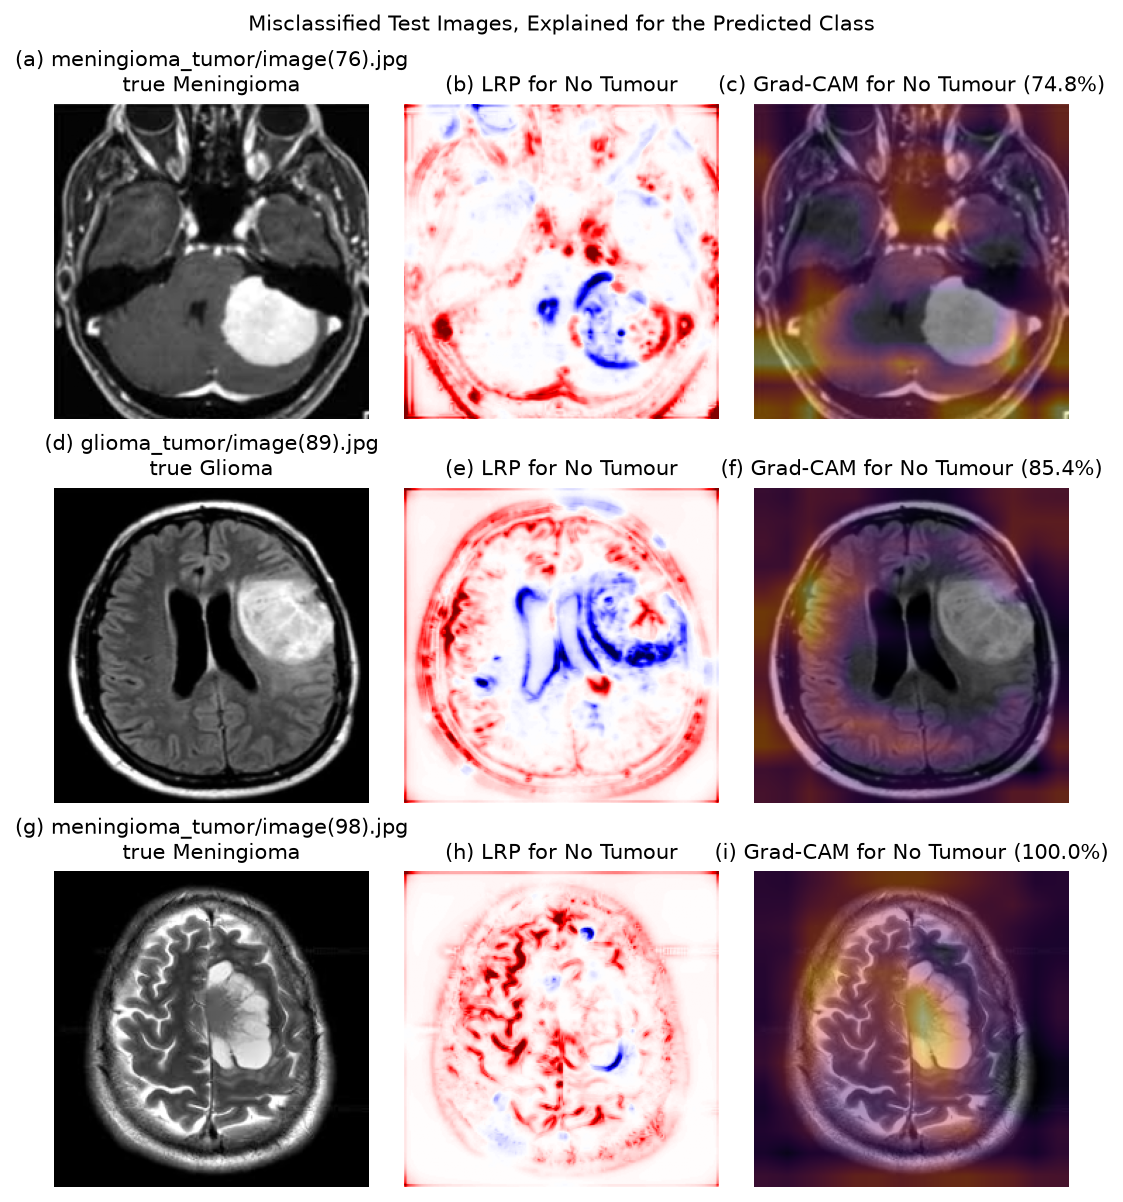

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(FIGURE_WIDTH, FIGURE_WIDTH + 0.9))
for row, i in zip(axes, error_cases, strict=True):
    image, target = normalise(test_images[i]), int(test.loc[i, "predicted"])
    show_image(row[0], image)
    show_lrp(row[1], lrp_heatmap(lrp(model, image, target)))
    show_grad_cam(row[2], image, grad_cam(model, image, target))
    row[0].set_title(f"{test.loc[i, 'file']}\ntrue {CLASS_LABELS[test.loc[i, 'label']]}", fontsize=8)
    row[1].set_title(f"LRP for {LABELS[target]}", fontsize=8)
    row[2].set_title(f"Grad-CAM for {LABELS[target]} ({test.loc[i, 'confidence']:.1%})", fontsize=8)
label_panels(axes.ravel())
fig.suptitle("Misclassified Test Images, Explained for the Predicted Class")
save_figure(fig, "06_errors")

<a id="sec-deletion"></a>

## 6. Faithfulness: deletion test

- **Method** (Samek et al., 2017): pixels are blacked out in the order a method ranks them, in steps of 5% up to 50% of the image; the probability of the originally predicted class is recorded after each step. Black = the background of every scan.
- **Comparison:** each method against itself, most relevant first (MoRF) vs least relevant first (LeRF). Scattered black pixels lower confidence whatever they mean (the random-order curve, in grey, drops most), so only the gap is read.
- **Score:** gap = LeRF AUC - MoRF AUC (area under the mean curve, as a share of the maximum); higher = more faithful.
- All 394 test images, each explained for its predicted class; AUCs for both test sets, curves for the Original set.

- **Grad-CAM is faithful:** blacking out its top-ranked pixels lowers the probability much faster than blacking out its lowest-ranked pixels (AUC 0.371 vs 0.640, gap 0.269; Clean\* 0.271).
- **LRP barely is:** its two curves stay close (AUC 0.445 vs 0.492, gap 0.047; Clean\* 0.055). Its top-ranked pixels are thin edges and outlines, which the model can do without.

In [8]:
STEPS = np.arange(0, 0.55, 0.05)
black = normalise(torch.zeros(3, 1, 1, dtype=torch.uint8))
rng = np.random.default_rng(SEED)


@torch.no_grad()
def deletion_curve(image: torch.Tensor, order: np.ndarray, target: int) -> np.ndarray:
    """Probability of ``target`` after blacking out the first 0%, 5%, ... 50% of pixels in ``order``."""
    batch = image.repeat(len(STEPS), 1, 1, 1)
    flat = batch.view(len(STEPS), 3, -1)
    for k, share in enumerate(STEPS):
        hidden = torch.as_tensor(order[: int(share * order.size)])
        flat[k][:, hidden] = black.view(3, 1)
    return torch.softmax(model(batch.to(device())), dim=1)[:, target].cpu().numpy()


curves = {"LRP MoRF": [], "LRP LeRF": [], "Grad-CAM MoRF": [], "Grad-CAM LeRF": [], "Random": []}
runtime = {"LRP": [], "Grad-CAM": []}
lrp_maps, cam_maps = [], []  # reused in Sections 7 and 8
for i in range(len(test)):
    image, target = normalise(test_images[i]), int(test.loc[i, "predicted"])
    start = time.perf_counter()
    relevance = lrp_heatmap(lrp(model, image, target))
    runtime["LRP"].append(time.perf_counter() - start)
    start = time.perf_counter()
    cam = grad_cam(model, image, target)
    runtime["Grad-CAM"].append(time.perf_counter() - start)
    lrp_maps.append(relevance)
    cam_maps.append(cam)
    for method, scores in [("LRP", relevance), ("Grad-CAM", cam)]:
        order = np.argsort(-scores.ravel(), kind="stable")
        curves[f"{method} MoRF"].append(deletion_curve(image, order, target))
        curves[f"{method} LeRF"].append(deletion_curve(image, order[::-1].copy(), target))
    curves["Random"].append(deletion_curve(image, rng.permutation(image[0].numel()), target))
curves = {name: np.array(values) for name, values in curves.items()}
deletion = {}
for set_name, rows in TEST_SETS.items():
    auc = {name: np.trapezoid(values[rows].mean(0), STEPS) / STEPS[-1] for name, values in curves.items()}
    for m in ["LRP", "Grad-CAM"]:
        deletion[set_name, m] = {
            "MoRF AUC": auc[f"{m} MoRF"],
            "LeRF AUC": auc[f"{m} LeRF"],
            "Gap (LeRF - MoRF)": auc[f"{m} LeRF"] - auc[f"{m} MoRF"],
            "Random AUC": auc["Random"],
        }
deletion = pd.DataFrame(deletion).T.rename_axis(["Test set", "Method"])
deletion_gap = deletion.loc["Original", "Gap (LeRF - MoRF)"].to_dict()
deletion.round(3)

MoRF AUC  LeRF AUC  Gap (LeRF - MoRF)  Random AUC
Test set Method                                                     
Original LRP          0.445     0.492              0.047       0.505
         Grad-CAM     0.371     0.640              0.269       0.505
Clean*   LRP          0.440     0.495              0.055       0.515
         Grad-CAM     0.374     0.645              0.271       0.515

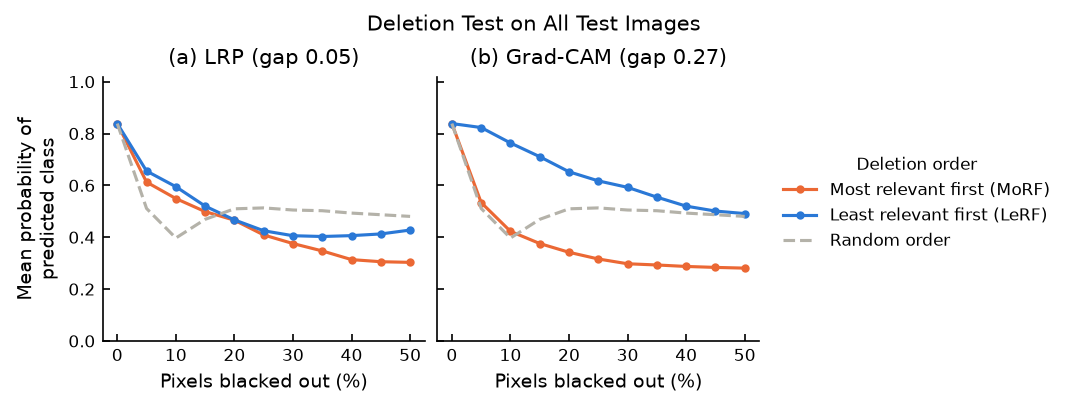

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(FIGURE_WIDTH, 2.6), sharey=True)
for ax, method in zip(axes, ["LRP", "Grad-CAM"], strict=True):
    ax.plot(
        STEPS * 100,
        curves[f"{method} MoRF"].mean(0),
        marker="o",
        markersize=3,
        color=COLORS["orange"],
        label="Most relevant first (MoRF)",
    )
    ax.plot(
        STEPS * 100,
        curves[f"{method} LeRF"].mean(0),
        marker="o",
        markersize=3,
        color=COLORS["blue"],
        label="Least relevant first (LeRF)",
    )
    ax.plot(STEPS * 100, curves["Random"].mean(0), color=COLORS["grey"], linestyle="--", label="Random order")
    ax.set_title(f"{method} (gap {deletion_gap[method]:.2f})")
    ax.set_xlabel("Pixels blacked out (%)")
    ax.set_ylim(0, 1.02)
axes[0].set_ylabel("Mean probability of\npredicted class")
label_panels(axes)
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside right center", title="Deletion order")
fig.suptitle("Deletion Test on All Test Images")
save_figure(fig, "06_deletion")

<a id="sec-background"></a>

## 7. Region relevance: evidence outside the head

- **Why:** image size is tied to class and split ([notebook 04](04_mri_eda.ipynb#sec-sizes)), so the model might use resizing traces or the image border instead of brain tissue; then much of the evidence would fall on the black background.
- **Region relevance score:** share of a method's positive evidence (positive LRP relevance; Grad-CAM values) inside a region, here the background (grey value < `0.05` of white), averaged per group.
- **Reading:** compared with the region's share of the image area; about equal = no preference for or against the region, lower = region used less than its size suggests.
- **Groups:** predicted class and modality\* (CT scans have a bright skull); Original test set.
- **Limitation:** the dataset has no tumour outlines, so the score cannot be computed for the tumour itself.

- **Overall:** background is 30.6% of the image area but holds 17.6% of LRP's and 28.8% of Grad-CAM's positive evidence; neither method suggests that the model mainly reads the black border.
- **CT\*:** Grad-CAM puts 51.3% of its evidence on background, more than the background area (42.3%); on CT, the model looks outside the head.
- **By class:** No Tumour predictions put 35.6% of Grad-CAM evidence on background (area 29.9%), Pituitary predictions only 3.7% (area 16.4%).
- The Unclear row is a single image without black background.

In [10]:
rows = []
for i, (relevance, cam) in enumerate(zip(lrp_maps, cam_maps, strict=True)):
    background = (test_images[i].float().mean(0) / 255 < 0.05).numpy()
    positive = np.clip(relevance, 0, None)
    rows.append(
        (
            LABELS[test.loc[i, "predicted"]],
            test.loc[i, "modality"],
            background.mean(),
            positive[background].sum() / positive.sum(),
            cam[background].sum() / cam.sum(),
        )
    )
outside = pd.DataFrame(
    rows, columns=["Predicted class", "Modality", "Background area", "LRP evidence", "Grad-CAM evidence"]
)
values = ["Background area", "LRP evidence", "Grad-CAM evidence"]
summary = pd.concat(
    {
        "Predicted class": outside.groupby("Predicted class")[values].mean(),
        "Modality*": outside.groupby("Modality")[values].mean(),
        "All": outside[values].mean().to_frame("All test images").T,
    }
)
summary.map("{:.1%}".format)

Background area LRP evidence Grad-CAM evidence
Predicted class Glioma                    33.4%        16.7%             17.4%
                Meningioma                34.1%        13.0%             28.9%
                No Tumour                 29.9%        20.6%             35.6%
                Pituitary                 16.4%        16.2%              3.7%
Modality*       CT                        42.3%        27.7%             51.3%
                MRI                       29.5%        16.6%             26.7%
                Unclear                    0.0%         0.0%              0.0%
All             All test images           30.6%        17.6%             28.8%

<a id="sec-comparison"></a>

## 8. Comparison

| Property | LRP | Grad-CAM |
|---|---|---|
| Resolution | Pixel (224 x 224) | Region (14 x 14, upsampled) |
| Evidence shown | For and against (signed) | For only (ReLU) |
| Model access | Rule per layer; written for each architecture | Any CNN; needs one convolutional layer |
| Best audience | Data scientist: fine detail, edges, evidence against | Doctor and patient: where the model looked |

- **Measured** on the Original test set: deletion gap, randomisation rank correlation, background evidence, runtime, and the overlap of the two methods' top-10% regions (intersection over union, IoU; one value for the pair).

- **Result:** Grad-CAM is more faithful (deletion gap 0.269 vs 0.047) and depends on the trained model (rank correlation -0.110 vs 0.690 after randomisation); LRP puts less evidence on background (17.6% vs 28.8%) and is about 30 times slower (median 0.431 vs 0.013 s per image, all 394 test images).
- **Overlap:** the two methods' top-10% regions overlap little (mean IoU 0.134), mostly because LRP picks thin edges and Grad-CAM picks blobs.
- **Implication:** Grad-CAM is the safer guide to *where* this model looks; LRP adds pixel detail and evidence against a class, useful for a data scientist but not a measure of importance on its own.

In [11]:
iou = []
for relevance, cam in zip(lrp_maps, cam_maps, strict=True):
    top_lrp, top_cam = relevance >= np.quantile(relevance, 0.9), cam >= np.quantile(cam, 0.9)
    iou.append((top_lrp & top_cam).sum() / (top_lrp | top_cam).sum())

all_images = summary.loc[("All", "All test images")]
comparison = pd.DataFrame(
    {
        method: {
            "Deletion gap, LeRF - MoRF (higher = more faithful)": deletion_gap[method],
            "Rank correlation after randomisation (lower = more model-dependent)": randomisation[
                method
            ].median(),
            "Evidence on background (area share in next row)": all_images[f"{method} evidence"],
            "Background share of image area": all_images["Background area"],
            "Median seconds per image (all 394 test images)": np.median(runtime[method]),
        }
        for method in ["LRP", "Grad-CAM"]
    }
)
comparison.loc["Top-10% region overlap, LRP vs Grad-CAM (mean IoU)"] = np.mean(iou)
comparison.round(3)

,LRP,Grad-CAM
"Deletion gap, LeRF - MoRF (higher = more faithful)",0.047,0.269
Rank correlation after randomisation (lower = more model-dependent),0.690,-0.110
Evidence on background (area share in next row),0.176,0.288
Background share of image area,0.306,0.306
Median seconds per image (all 394 test images),0.431,0.013
"Top-10% region overlap, LRP vs Grad-CAM (mean IoU)",0.134,0.134


<a id="sec-takeaways"></a>

## 9. Key takeaways

1. **Grad-CAM is the more trustworthy method** ([Section 2](#sec-gradcam), [Section 6](#sec-deletion)): it passes the randomisation check and has the larger deletion gap; LRP fails randomisation and its deletion gap is small (rank correlation -0.110 vs 0.690; gap 0.269 vs 0.047).
2. **Both methods agree on the main case** ([Section 4](#sec-main)): the Meningioma prediction rests on the tumour.
3. **Correct is not the same as right for the right reason** ([Section 3](#sec-local)): for the pituitary case, neither method points to the tumour.
4. **Missed tumours are explainable** ([Section 5](#sec-errors)): either the tumour counts against No Tumour but normal tissue outweighs it, or, on a T2-like scan\*, the lesion itself is read as normal, at 100.0% confidence.
5. **CT scans pull evidence outside the head** ([Section 7](#sec-background)): 51.3% of Grad-CAM evidence on background for CT\*, against 26.7% for MRI\*.
6. **Audience fit** ([Section 8](#sec-comparison)): Grad-CAM for doctors and patients (regions, fast, faithful); LRP for data scientists (pixel detail, evidence against).

<a id="sec-references"></a>

## 10. References

Adebayo, J., Gilmer, J., Muelly, M., Goodfellow, I., Hardt, M., & Kim, B. (2018). Sanity checks for saliency maps. *Advances in Neural Information Processing Systems, 31*, 9505-9515. https://doi.org/10.48550/arXiv.1810.03292

Kokhlikyan, N., Miglani, V., Martin, M., Wang, E., Alsallakh, B., Reynolds, J., Melnikov, A., Kliushkina, N., Araya, C., Yan, S., & Reblitz-Richardson, O. (2020). *Captum: A unified and generic model interpretability library for PyTorch*. arXiv. https://doi.org/10.48550/arXiv.2009.07896

Samek, W., Binder, A., Montavon, G., Lapuschkin, S., & Müller, K.-R. (2017). Evaluating the visualization of what a deep neural network has learned. *IEEE Transactions on Neural Networks and Learning Systems, 28*(11), 2660-2673. https://doi.org/10.1109/TNNLS.2016.2599820

Selvaraju, R. R., Cogswell, M., Das, A., Vedantam, R., Parikh, D., & Batra, D. (2017). Grad-CAM: Visual explanations from deep networks via gradient-based localization. *Proceedings of the IEEE International Conference on Computer Vision*, 618-626. https://doi.org/10.1109/ICCV.2017.74